# Baseline 모델 구축
**불균형 처리 없이 6개 분류 모델을 동일한 조건으로 학습·평가하여 이후 실험의 비교 기준을 만듭니다.**

| 항목 | 설정 |
|---|---|
| 데이터 | `data/processed/Faults_processed.csv` (입력 26개 + `target`), 팀 공통 `load_data()` |
| 분할 | Train 1,552 / Test 389 (Stratified 80:20, `random_state=42`) — **이 노트북은 Train만 사용** |
| 검증 | Train 내부 `StratifiedKFold(5, shuffle=True, random_state=42)` (팀 `config.CV`) |
| 모델 | Logistic Regression, Decision Tree, Random Forest, GradientBoostingClassifier (팀 공통 4개) + XGBoost, LightGBM (Boosting 계열 추가 후보) |
| 하이퍼파라미터 | 기본값 (`random_state=42`). 예외: LR `max_iter=5000` (수렴 점검 결과, 2번 참고) |
| 불균형 처리 | **적용하지 않음** (`class_weight`, `sample_weight`, Sampling 모두 없음) |
| 전처리 | Pipeline 내부 — LR: 결측 대체 + StandardScaler(연속형만) / Tree 계열: 결측 대체만 |
| 핵심 지표 | **Macro F1** (목표 ≥ 0.83) + Accuracy, Macro Precision/Recall, Weighted F1, Macro ROC-AUC(OvR) |

> **Test 데이터는 최종 모델 선정 후 1회만 사용합니다.** 클래스별 지표와 혼동행렬은 CV의 **out-of-fold(OOF) 예측**으로 계산합니다.
> OOF 예측은 Train의 각 행을 "그 행을 학습에 쓰지 않은 fold 모델"이 예측한 값이므로, Test를 쓰지 않고도 일반화 오류를 분석할 수 있습니다.

In [1]:
import sys, warnings, time
from pathlib import Path
from sklearn.base import clone

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, MINORITY_CLASSES, SCORING_EXTENDED, make_pipeline, run_many,
                         summarize_cv, per_class_report, confusion_df, key_error_counts, oof_macro_f1)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from Taegyeom_model_utils import LabelEncodedClassifier   # XGBoost는 정수 라벨만 받으므로 문자열 라벨 변환 래퍼 사용

RESULT_DIR = PROJECT_ROOT / "results" / "baseline"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

# ---- 시각화 공통 스타일 ----
BLUE, BLUE_LIGHT, RED = "#2a78d6", "#86b6ef", "#e34948"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

## 1. 데이터 불러오기

In [2]:
X_train, X_test, y_train, y_test = load_data()
FEATURES = list(X_train.columns)
print("X_train:", X_train.shape, "| y_train:", y_train.shape, "  (X_test/y_test는 최종 모델 평가 전까지 사용하지 않음)")
assert "TypeOfSteel_A400" not in FEATURES and len(FEATURES) == 26
assert set(y_train.unique()) == set(CLASS_ORDER)

train_dist = y_train.value_counts().reindex(CLASS_ORDER).to_frame("Train 건수")
train_dist["CV 검증 fold당(약)"] = (train_dist["Train 건수"] / 5).round().astype(int)
train_dist.T

X_train: (1552, 26) | y_train: (1552,)   (X_test/y_test는 최종 모델 평가 전까지 사용하지 않음)


target,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness
Train 건수,538,321,313,152,126,58,44
CV 검증 fold당(약),108,64,63,30,25,12,9


## 2. Logistic Regression 수렴 점검
과제 안내에서 *"기본 로지스틱 회귀에서 수렴 경고가 있었다"* 고 했으므로, 기본 `max_iter=100`과 충분히 큰 `max_iter=5000`을 같은 조건으로 비교합니다.

In [3]:
lr_check = {
    "LR (max_iter=100, 기본값)": make_pipeline(LogisticRegression(random_state=RANDOM_STATE), FEATURES, scale=True),
    "LR (max_iter=5000)": make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), FEATURES, scale=True),
}
lr_res = list(run_many({k: dict(build=lambda m=m: clone(m)) for k, m in lr_check.items()}, X_train, y_train).values())
conv_tbl = summarize_cv(lr_res)[["macro_f1_mean", "macro_f1_std", "accuracy_mean", "convergence_warnings"]]

# 수렴에 실제로 필요한 반복 횟수 (Train 전체로 1회 fit, 참고용)
fitted = lr_check["LR (max_iter=5000)"].fit(X_train, y_train)
conv_tbl["필요 반복 수(n_iter_)"] = ["—", int(fitted.named_steps["model"].n_iter_.max())]
conv_tbl.round(4)

,macro_f1_mean,macro_f1_std,accuracy_mean,convergence_warnings,필요 반복 수(n_iter_)
model,,,,,
"LR (max_iter=100, 기본값)",0.7194,0.0256,0.7145,5,—
LR (max_iter=5000),0.7191,0.0275,0.7132,0,135


**확인 결과**
- 기본값 `max_iter=100`에서는 5개 fold의 모든 fit에서 `ConvergenceWarning`이 발생했습니다. **수렴하지 않은 모델**이라는 뜻입니다.
- `max_iter=5000`으로 늘리면 경고가 사라집니다. 실제 수렴에는 약 135회의 반복이 필요합니다(위 표, Train 전체 fit 기준).
- 두 설정의 Macro F1 차이는 0.001 이하로 미미합니다. 그래도 **수렴한 모델을 비교 기준으로 쓰는 것이 공정**하므로 Baseline LR은 `max_iter=5000`을 사용합니다.
  StandardScaler가 이미 적용되어 있어 스케일 문제로 인한 수렴 실패는 아니고, 다중 클래스(multinomial) 최적화에 필요한 반복 수가 기본값을 약간 넘는 경우입니다.

## 3. Baseline 모델 정의 및 5-fold CV

In [4]:
baseline_models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), FEATURES, scale=True),
    "Decision Tree":       make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), FEATURES),
    "Random Forest":       make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), FEATURES),
    "GBM":                 make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), FEATURES),
    "XGBoost":             make_pipeline(LabelEncodedClassifier(XGBClassifier(random_state=RANDOM_STATE, n_jobs=1)), FEATURES),
    "LightGBM":            make_pipeline(LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1), FEATURES),
}
# (모델 × fold) 30개 학습을 CPU 코어 수만큼 병렬 실행 — 모델 내부 n_jobs=1로 과점유 방지
t0 = time.perf_counter()
res_map = run_many({name: dict(build=lambda p=pipe: clone(p)) for name, pipe in baseline_models.items()}, X_train, y_train)
results = [res_map[n] for n in baseline_models]
for r in results:
    print(f"{r['name']:20s} Macro F1 {r['folds']['val_macro_f1'].mean():.4f} ± {r['folds']['val_macro_f1'].std(ddof=0):.4f}"
          f"   (수렴경고 {r['n_conv_warn']})")
print(f"총 소요 {time.perf_counter() - t0:.1f}초")

Logistic Regression  Macro F1 0.7191 ± 0.0275   (수렴경고 0)
Decision Tree        Macro F1 0.7207 ± 0.0259   (수렴경고 0)
Random Forest        Macro F1 0.7899 ± 0.0312   (수렴경고 0)
GBM                  Macro F1 0.7963 ± 0.0101   (수렴경고 0)
XGBoost              Macro F1 0.8109 ± 0.0308   (수렴경고 0)
LightGBM             Macro F1 0.8044 ± 0.0360   (수렴경고 0)
총 소요 21.1초


In [5]:
summary = summarize_cv(results)
summary.to_csv(RESULT_DIR / "Taegyeom_baseline_cv_summary.csv")
pd.concat([r["folds"] for r in results]).to_csv(RESULT_DIR / "Taegyeom_baseline_cv_folds.csv", index=False)
pd.concat([r["oof"] for r in results], axis=1).assign(y_true=y_train).to_csv(RESULT_DIR / "Taegyeom_baseline_oof_predictions.csv")

# 과제 비교표 양식: 모델 | 불균형 처리 | Accuracy | Precision | Recall | F1 | 핵심 지표
fmt = lambda m, s: f"{m:.4f} ± {s:.4f}"
table = pd.DataFrame({
    "불균형 처리": "적용 전",
    "Accuracy": [fmt(summary.loc[n, "accuracy_mean"], summary.loc[n, "accuracy_std"]) for n in summary.index],
    "Precision (macro)": [fmt(summary.loc[n, "macro_precision_mean"], summary.loc[n, "macro_precision_std"]) for n in summary.index],
    "Recall (macro)": [fmt(summary.loc[n, "macro_recall_mean"], summary.loc[n, "macro_recall_std"]) for n in summary.index],
    "F1 (weighted)": [fmt(summary.loc[n, "weighted_f1_mean"], summary.loc[n, "weighted_f1_std"]) for n in summary.index],
    "ROC-AUC (macro OvR)": [fmt(summary.loc[n, "macro_roc_auc_ovr_mean"], summary.loc[n, "macro_roc_auc_ovr_std"]) for n in summary.index],
    "핵심 지표: Macro F1": [fmt(summary.loc[n, "macro_f1_mean"], summary.loc[n, "macro_f1_std"]) for n in summary.index],
    "목표(0.83)까지": [f"{0.83 - summary.loc[n, 'macro_f1_mean']:+.4f}" for n in summary.index],
}, index=summary.index)
table.to_csv(RESULT_DIR / "Taegyeom_baseline_comparison_table.csv")
table

,불균형 처리,Accuracy,Precision (macro),Recall (macro),F1 (weighted),ROC-AUC (macro OvR),핵심 지표: Macro F1,목표(0.83)까지
model,,,,,,,,
Logistic Regression,적용 전,0.7132 ± 0.0163,0.7324 ± 0.0245,0.7156 ± 0.0367,0.7104 ± 0.0161,0.9308 ± 0.0060,0.7191 ± 0.0275,+0.1109
Decision Tree,적용 전,0.7075 ± 0.0170,0.7218 ± 0.0255,0.7288 ± 0.0273,0.7052 ± 0.0177,0.8367 ± 0.0145,0.7207 ± 0.0259,+0.1093
Random Forest,적용 전,0.7719 ± 0.0153,0.8196 ± 0.0183,0.7718 ± 0.0404,0.7704 ± 0.0158,0.9609 ± 0.0031,0.7899 ± 0.0312,+0.0401
GBM,적용 전,0.7790 ± 0.0086,0.8137 ± 0.0056,0.7852 ± 0.0189,0.7780 ± 0.0087,0.9584 ± 0.0045,0.7963 ± 0.0101,+0.0337
XGBoost,적용 전,0.7945 ± 0.0171,0.8352 ± 0.0212,0.7997 ± 0.0397,0.7918 ± 0.0178,0.9639 ± 0.0046,0.8109 ± 0.0308,+0.0191
LightGBM,적용 전,0.7893 ± 0.0230,0.8266 ± 0.0252,0.7936 ± 0.0474,0.7875 ± 0.0237,0.9606 ± 0.0034,0.8044 ± 0.0360,+0.0256


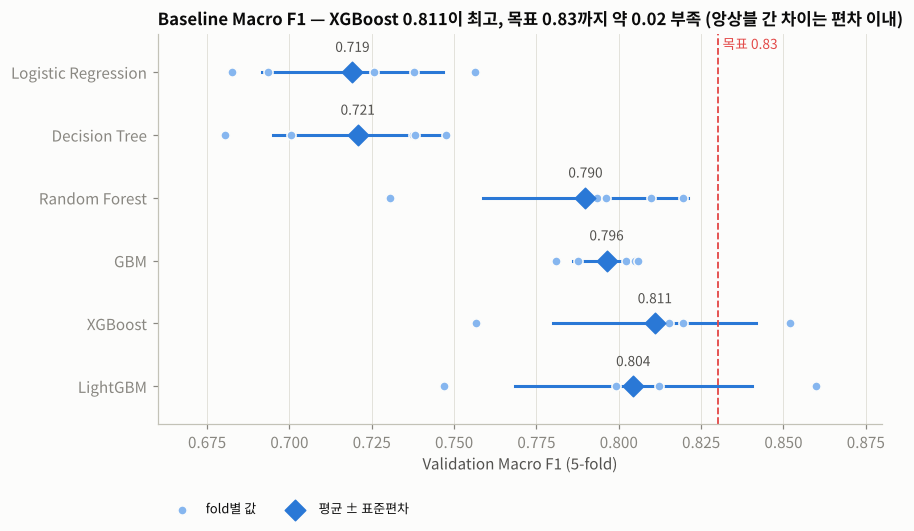

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
names = list(summary.index)
for i, n in enumerate(names):
    v = results[i]["folds"]["val_macro_f1"].values
    ax.scatter(v, [i] * len(v), s=36, color=BLUE_LIGHT, edgecolor=SURFACE, linewidth=1, zorder=3, label="fold별 값" if i == 0 else None)
    m, s = v.mean(), v.std(ddof=0)
    ax.plot([m - s, m + s], [i, i], color=BLUE, lw=2, zorder=2)
    ax.scatter([m], [i], s=90, color=BLUE, zorder=4, marker="D", label="평균 ± 표준편차" if i == 0 else None)
    ax.text(m, i - 0.32, f"{m:.3f}", ha="center", fontsize=9, color=INK2)
ax.axvline(0.83, color=RED, lw=1.2, ls="--"); ax.text(0.8315, -0.45, "목표 0.83", color=RED, fontsize=9, va="center")
ax.set_yticks(range(len(names)), names); ax.invert_yaxis(); ax.set_ylim(len(names) - 0.4, -0.6)
ax.set_xlim(0.66, 0.88); ax.grid(axis="y", visible=False); ax.set_xlabel("Validation Macro F1 (5-fold)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.17), frameon=False, fontsize=8.5, ncol=2)
ax.set_title("Baseline Macro F1 — XGBoost 0.811이 최고, 목표 0.83까지 약 0.02 부족 (앙상블 간 차이는 편차 이내)")
save(fig, "Taegyeom_baseline_macro_f1_cv.png")

**해석 — 전체 지표**
- **XGBoost(0.811 ± 0.031)가 가장 높고**, LightGBM(0.804), GBM(0.796), Random Forest(0.790)가 뒤를 잇습니다. LR(0.719)과 Decision Tree(0.721)는 약 0.09 낮습니다.
- 상위 4개 앙상블의 평균 차이(최대 0.021)는 fold 간 표준편차(0.01~0.036)와 비슷하거나 작아 **우열이 통계적으로 뚜렷하지 않습니다.**
  GBM은 평균은 약간 낮지만 편차가 0.010으로 가장 안정적이고, XGBoost·LightGBM은 평균이 높은 대신 fold에 따라 ±0.03 이상 흔들립니다.
- XGBoost는 Macro Precision(0.835)과 Macro Recall(0.800)이 모두 가장 높아, 특정 지표를 희생하지 않고 전반적으로 우수합니다.
- 모든 모델에서 Macro F1이 Accuracy·Weighted F1보다 높거나 비슷합니다. 소수 클래스 성능이 다수 클래스보다 크게 떨어지지 않는다는 뜻으로, 원인은 5번에서 확인합니다.
- 목표 0.83까지 최고 모델 기준 **약 0.019가 부족**합니다 → 이후 클래스 불균형 처리와 하이퍼파라미터 튜닝의 개선 목표입니다.

## 4. 과적합 점검 (Train fold vs Validation fold)

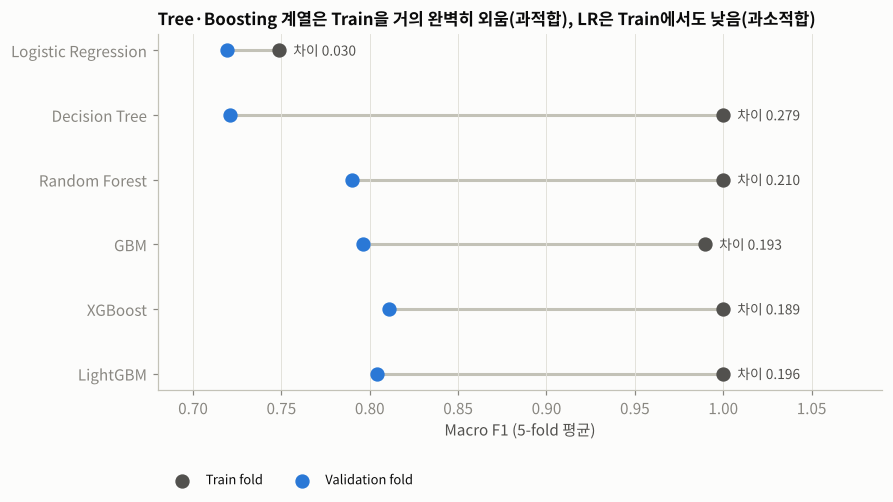

,train_macro_f1,macro_f1_mean,overfit_gap_macro_f1,fit_time_sec
model,,,,
Logistic Regression,0.7488,0.7191,0.0296,0.1073
Decision Tree,1.0000,0.7207,0.2793,0.0351
Random Forest,1.0000,0.7899,0.2101,0.5296
GBM,0.9897,0.7963,0.1935,4.7718
XGBoost,1.0000,0.8109,0.1891,0.7634
LightGBM,1.0000,0.8044,0.1956,1.3563


In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for i, n in enumerate(names):
    tr, va = summary.loc[n, "train_macro_f1"], summary.loc[n, "macro_f1_mean"]
    ax.plot([va, tr], [i, i], color=AXIS, lw=2, zorder=1)
    ax.scatter([tr], [i], s=70, color=INK2, zorder=3, label="Train fold" if i == 0 else None)
    ax.scatter([va], [i], s=70, color=BLUE, zorder=3, label="Validation fold" if i == 0 else None)
    ax.text(tr + 0.008, i, f"차이 {tr - va:.3f}", va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(names)), names); ax.invert_yaxis(); ax.set_xlim(0.68, 1.09)
ax.grid(axis="y", visible=False); ax.set_xlabel("Macro F1 (5-fold 평균)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.2), frameon=False, fontsize=8.5, ncol=2)
ax.set_title("Tree·Boosting 계열은 Train을 거의 완벽히 외움(과적합), LR은 Train에서도 낮음(과소적합)")
save(fig, "Taegyeom_baseline_overfitting_gap.png")
summary[["train_macro_f1", "macro_f1_mean", "overfit_gap_macro_f1", "fit_time_sec"]].round(4)

**해석**
- **Decision Tree·Random Forest·XGBoost·LightGBM은 Train Macro F1 = 1.000**, GBM도 0.990으로 학습 데이터를 거의 외웁니다. Validation과의 차이는 0.19~0.28로 **과적합**이 뚜렷합니다.
  기본값이 트리를 깊게(또는 많이) 키우기 때문이며, 이후 하이퍼파라미터 튜닝에서 `max_depth`, `min_child_weight`/`min_samples_leaf`, `learning_rate`, `subsample` 등을 조정할 근거가 됩니다.
- **Logistic Regression은 Train(0.749)과 Validation(0.719)이 모두 낮습니다.** 과적합이 아니라 선형 결정경계의 한계로 인한 **과소적합**입니다.
  EDA에서 확인한 강한 왜도(면적·밝기)와 비선형 관계가 원인일 수 있어, log1p 변환 실험의 근거가 됩니다.
- 학습 시간은 sklearn GBM이 fold당 약 5초로 가장 느리고, XGBoost·LightGBM은 1초 미만으로 **튜닝 반복에 유리**합니다.

## 5. 클래스별 Precision · Recall · F1 (OOF 예측, Train 1,552건)

In [8]:
reports = {r["name"]: per_class_report(y_train, r["oof"]) for r in results}
per_class = pd.concat(reports, names=["model", "class"])
per_class.to_csv(RESULT_DIR / "Taegyeom_baseline_per_class_oof.csv")

for metric in ["precision", "recall", "f1"]:
    t = per_class[metric].unstack("class")[CLASS_ORDER].reindex(names)
    t["macro"] = t.mean(axis=1)
    print(f"\n[{metric.upper()}]"); display(t.round(3))
print("\nOOF Macro F1:", {n: round(oof_macro_f1(y_train, r["oof"]), 4) for n, r in zip(names, results)},
      "\n(fold 평균과 약간 다른 이유: OOF는 1,552건 전체를 한 번에 계산한 값)")


[PRECISION]


class,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,macro
model,,,,,,,,
Logistic Regression,0.629,0.626,0.930,0.788,0.575,0.915,0.649,0.730
Decision Tree,0.651,0.550,0.946,0.848,0.504,0.844,0.667,0.716
Random Forest,0.686,0.665,0.980,0.890,0.685,0.930,0.895,0.818
GBM,0.710,0.658,0.965,0.959,0.629,0.912,0.854,0.812
XGBoost,0.733,0.670,0.971,0.954,0.627,0.947,0.921,0.832
LightGBM,0.726,0.672,0.965,0.928,0.653,0.947,0.872,0.823



[RECALL]


class,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,macro
model,,,,,,,,
Logistic Regression,0.677,0.558,0.930,0.855,0.516,0.931,0.545,0.716
Decision Tree,0.638,0.564,0.955,0.882,0.452,0.931,0.682,0.729
Random Forest,0.766,0.654,0.949,0.849,0.500,0.914,0.773,0.772
GBM,0.755,0.660,0.955,0.914,0.524,0.897,0.795,0.786
XGBoost,0.771,0.682,0.965,0.947,0.508,0.931,0.795,0.800
LightGBM,0.764,0.682,0.958,0.928,0.524,0.931,0.773,0.794



[F1]


class,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,macro
model,,,,,,,,
Logistic Regression,0.652,0.590,0.930,0.820,0.544,0.923,0.593,0.722
Decision Tree,0.644,0.557,0.951,0.865,0.477,0.885,0.674,0.722
Random Forest,0.723,0.659,0.964,0.869,0.578,0.922,0.829,0.792
GBM,0.732,0.659,0.960,0.936,0.571,0.904,0.824,0.798
XGBoost,0.752,0.676,0.968,0.950,0.561,0.939,0.854,0.814
LightGBM,0.745,0.677,0.962,0.928,0.581,0.939,0.819,0.807



OOF Macro F1: {'Logistic Regression': 0.7216, 'Decision Tree': 0.7218, 'Random Forest': 0.7921, 'GBM': 0.798, 'XGBoost': 0.8143, 'LightGBM': 0.8072} 
(fold 평균과 약간 다른 이유: OOF는 1,552건 전체를 한 번에 계산한 값)


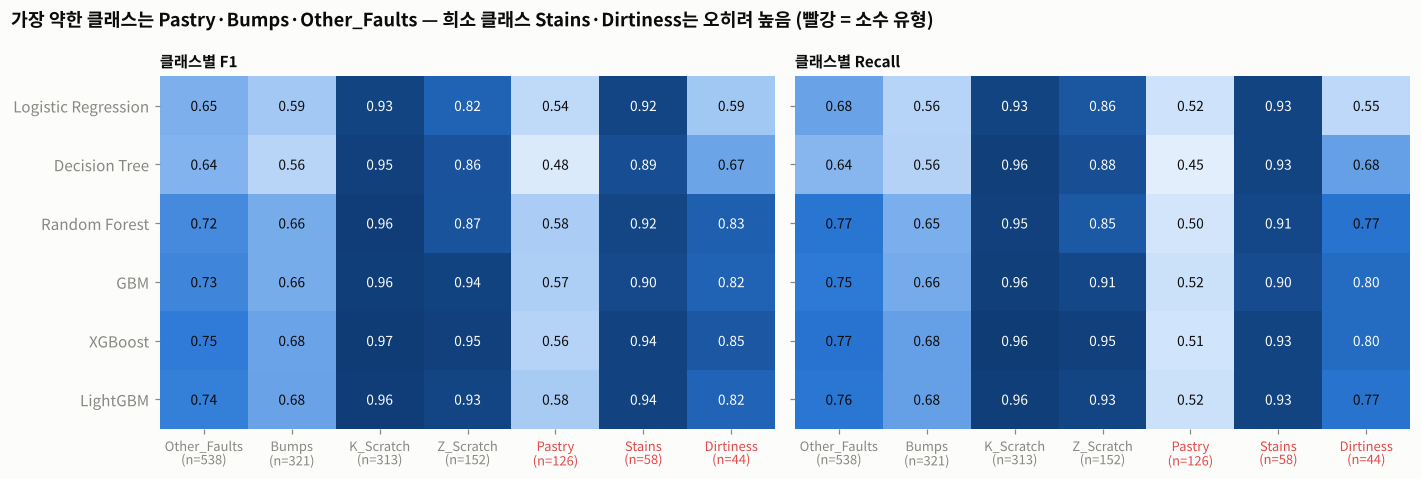

In [9]:
f1_mat = per_class["f1"].unstack("class")[CLASS_ORDER].reindex(names)
rec_mat = per_class["recall"].unstack("class")[CLASS_ORDER].reindex(names)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, mat, ttl in [(axes[0], f1_mat, "클래스별 F1"), (axes[1], rec_mat, "클래스별 Recall")]:
    im = ax.imshow(mat.values, cmap=SEQ, vmin=0.4, vmax=1.0, aspect="auto")
    ax.set_xticks(range(7), [f"{c}\n(n={int(s)})" for c, s in zip(CLASS_ORDER, reports[names[0]]["support"])], fontsize=8.5)
    ax.set_yticks(range(len(names)), names)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.78 else INK)
    ax.grid(False); ax.set_title(ttl, fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
    for lbl in ax.get_xticklabels():
        if lbl.get_text().split("\n")[0] in MINORITY_CLASSES: lbl.set_color(RED)
fig.suptitle("가장 약한 클래스는 Pastry·Bumps·Other_Faults — 희소 클래스 Stains·Dirtiness는 오히려 높음 (빨강 = 소수 유형)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "Taegyeom_baseline_per_class_f1_recall.png")

**해석 — 어떤 클래스를 잘/못 맞히는가**
- **잘 맞히는 클래스**: K_Scratch(F1 0.93~0.97), Stains(0.89~0.94), Z_Scratch(0.82~0.95).
  EDA에서 확인한 대로 크기(K_Scratch 대형·Stains 초소형), 위치(X축 가장자리), 강종(A300/A400)으로 거의 분리되는 유형입니다.
  **Stains는 건수가 적어도(58건) 특징이 뚜렷하면 불균형 처리 없이도 잘 맞힐 수 있음**을 보여줍니다.
- **Dirtiness(44건)** 는 모델 간 차이가 큽니다. LR 0.59 → 앙상블 0.82~0.85로, 비선형 모델에서 크게 좋아집니다.
  다만 OOF 기준 44건뿐이라 1건이 Recall 약 2.3%p에 해당해 불확실성이 큽니다.
- **가장 약한 클래스는 Pastry(F1 0.48~0.58, Recall 0.45~0.52)** 입니다. 모든 모델이 실제 Pastry의 절반가량을 놓치며, 앙상블을 바꿔도 거의 개선되지 않는 **최대 병목**입니다.
- **Bumps(0.56~0.68)와 Other_Faults(0.64~0.75)** 도 낮습니다. 건수가 많은 다수 클래스인데도 낮은 이유는 서로 간의 혼동 때문입니다(6번).
- 즉 이 데이터의 어려움은 *"희소해서 못 맞힌다"* 보다 **"측정 특성이 겹치는 유형(Pastry·Bumps·Other_Faults)을 구분하기 어렵다"** 에 가깝습니다.
  이후 클래스 불균형 처리로 Pastry·Dirtiness의 Recall은 오를 수 있지만, Other_Faults와의 경계 혼동 자체를 해결하지는 못할 수 있습니다.

## 6. Confusion Matrix (OOF 예측)
각 칸의 색과 위쪽 숫자는 **실제 클래스 대비 비율(행 기준, %)**, 괄호 안은 **건수**입니다. 대각선은 클래스별 Recall입니다.

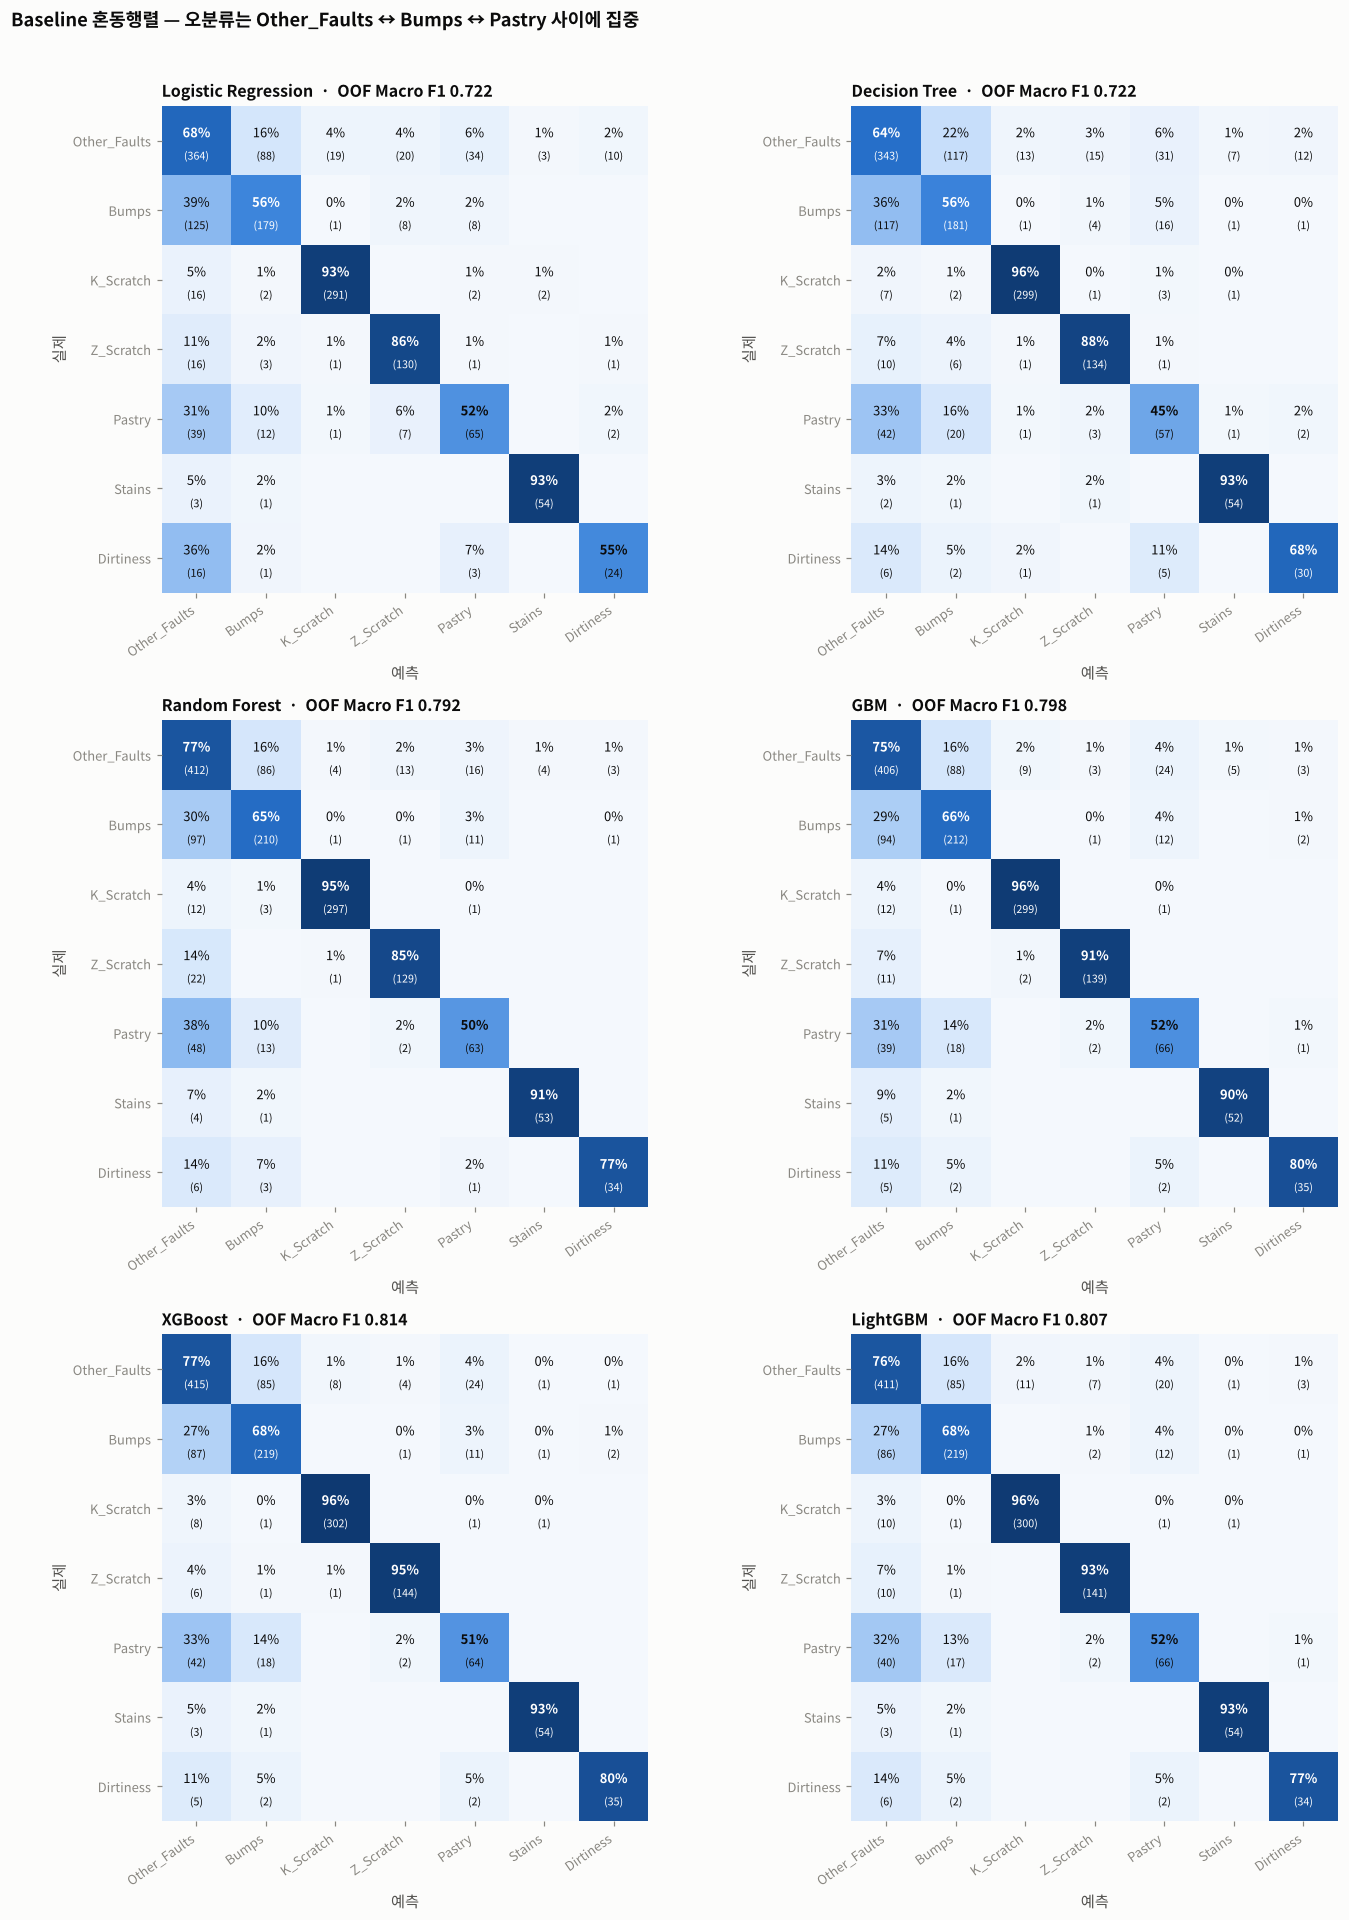

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(13, 17.5))
for ax, r in zip(axes.ravel(), results):
    cnt = confusion_df(y_train, r["oof"]); pct = confusion_df(y_train, r["oof"], normalize="true") * 100
    cnt.to_csv(RESULT_DIR / f"Taegyeom_baseline_confusion_oof_{r['name'].replace(' ', '_')}.csv")
    ax.imshow(pct.values, cmap=SEQ, vmin=0, vmax=100)
    for i in range(7):
        for j in range(7):
            c, p = cnt.values[i, j], pct.values[i, j]
            if c == 0: continue
            col = "white" if p > 55 else INK
            ax.text(j, i - 0.12, f"{p:.0f}%", ha="center", va="center", fontsize=8.5, color=col, fontweight="bold" if i == j else None)
            ax.text(j, i + 0.22, f"({c})", ha="center", va="center", fontsize=7, color=col)
    ax.set_xticks(range(7), CLASS_ORDER, rotation=35, ha="right", fontsize=8.5); ax.set_yticks(range(7), CLASS_ORDER, fontsize=8.5)
    ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"{r['name']}  ·  OOF Macro F1 {oof_macro_f1(y_train, r['oof']):.3f}", fontsize=10.5)
fig.suptitle("Baseline 혼동행렬 — 오분류는 Other_Faults ↔ Bumps ↔ Pastry 사이에 집중", x=0.01, y=0.995, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.985)); save(fig, "Taegyeom_baseline_confusion_matrices.png")

In [11]:
# 평가 기준에서 정의한 주요 오분류 유형별 건수 (OOF, Train 1,552건)
key_err = pd.DataFrame({r["name"]: key_error_counts(y_train, r["oof"]) for r in results}).T
key_err["Bumps↔Other 비중(%)"] = (key_err["Bumps ↔ Other_Faults"] / key_err["전체 오분류"] * 100).round(1)
key_err.to_csv(RESULT_DIR / "Taegyeom_baseline_key_errors_oof.csv")
display(key_err)

# 소수 유형이 어디로 오분류되는지 (최고 모델 GBM 기준)
best = max(results, key=lambda r: r["folds"]["val_macro_f1"].mean())
cnt_best = confusion_df(y_train, best["oof"])
print(f"[{best['name']}] 소수 유형별 오분류 행선지 (건수)")
cnt_best.loc[MINORITY_CLASSES].assign(**{"정답 수": lambda d: np.diag(cnt_best.loc[MINORITY_CLASSES, MINORITY_CLASSES])})

,소수 유형 → Other_Faults·Bumps,Other_Faults → 소수 유형 (오경보),Bumps ↔ Other_Faults,K_Scratch ↔ Z_Scratch,전체 오분류,Bumps↔Other 비중(%)
Logistic Regression,72,47,213,1,445,47.9
Decision Tree,73,50,234,2,454,51.5
Random Forest,75,23,183,1,354,51.7
GBM,70,32,182,2,343,53.1
XGBoost,71,26,172,1,319,53.9
LightGBM,69,24,171,0,327,52.3


[XGBoost] 소수 유형별 오분류 행선지 (건수)


예측,Other_Faults,Bumps,K_Scratch,Z_Scratch,Pastry,Stains,Dirtiness,정답 수
실제,,,,,,,,
Pastry,42,18,0,2,64,0,0,64
Stains,3,1,0,0,0,54,0,54
Dirtiness,5,2,0,0,2,0,35,35


**해석 — 주요 오분류**
1. **Bumps ↔ Other_Faults가 전체 오분류의 약 절반(48~54%)** 을 차지합니다(앙상블 기준 약 170~180건). 두 다수 클래스는 대부분의 측정 특성 범위가 겹쳐(EDA 참고)
   모델 종류와 무관하게 가장 큰 오류원입니다.
2. **소수 유형 → Other_Faults·Bumps는 69~75건**으로 모델 간 차이가 거의 없습니다. 그 대부분은 **Pastry**에서 나옵니다
   (XGBoost 기준 Pastry 126건 중 60건, 약 48%가 Other_Faults·Bumps로 흡수 — 소수 유형 흡수 71건 중 60건). 문제 정의에서 가장 중요하다고 정의한 오류가 여기에 해당합니다.
3. **Other_Faults → 소수 유형(오경보)은 앙상블 23~32건**으로 LR·DT(47~50건)보다 적습니다. 앙상블이 소수 유형을 더 "신중하게" 예측하기 때문이며,
   불균형 처리를 적용하면 이 수치가 증가할 가능성이 큽니다(클래스 불균형 처리에서 추적할 Trade-off).
4. **K_Scratch ↔ Z_Scratch는 0~2건**으로 사실상 문제가 되지 않습니다.

## 7. Baseline 결론 및 이후 과제

In [12]:
best_name = summary["macro_f1_mean"].idxmax()
print(f"최고 Baseline: {best_name}  Macro F1 {summary.loc[best_name, 'macro_f1_mean']:.4f} ± {summary.loc[best_name, 'macro_f1_std']:.4f}")
print(f"목표 0.83까지: {0.83 - summary.loc[best_name, 'macro_f1_mean']:.4f}")
print("\n저장 파일:"); [print(" -", p.relative_to(PROJECT_ROOT)) for p in sorted(RESULT_DIR.glob("*.csv"))]
[print(" -", p.relative_to(PROJECT_ROOT)) for p in sorted(FIG_DIR.glob("Taegyeom_baseline_*.png"))];

최고 Baseline: XGBoost  Macro F1 0.8109 ± 0.0308
목표 0.83까지: 0.0191

저장 파일:
 - results/baseline/Taegyeom_baseline_comparison_table.csv
 - results/baseline/Taegyeom_baseline_confusion_oof_Decision_Tree.csv
 - results/baseline/Taegyeom_baseline_confusion_oof_GBM.csv
 - results/baseline/Taegyeom_baseline_confusion_oof_LightGBM.csv
 - results/baseline/Taegyeom_baseline_confusion_oof_Logistic_Regression.csv
 - results/baseline/Taegyeom_baseline_confusion_oof_Random_Forest.csv
 - results/baseline/Taegyeom_baseline_confusion_oof_XGBoost.csv
 - results/baseline/Taegyeom_baseline_cv_folds.csv
 - results/baseline/Taegyeom_baseline_cv_summary.csv
 - results/baseline/Taegyeom_baseline_key_errors_oof.csv
 - results/baseline/Taegyeom_baseline_oof_predictions.csv
 - results/baseline/Taegyeom_baseline_per_class_oof.csv
 - figures/Taegyeom_baseline_confusion_matrices.png
 - figures/Taegyeom_baseline_macro_f1_cv.png
 - figures/Taegyeom_baseline_overfitting_gap.png
 - figures/Taegyeom_baseline_per_class_f1_

| 항목 | Baseline 결과 | 다음 단계에서의 의미 |
|---|---|---|
| 최고 모델 | **XGBoost 0.811 ± 0.031**, LightGBM 0.804, GBM 0.796(편차 최소), RF 0.790 | 차이가 편차 이내 → XGBoost·LightGBM·GBM·RF를 불균형 처리 후보로, LR·DT는 비교 기준으로 유지 |
| 목표 대비 | 0.83까지 약 **0.019** 부족 | 불균형 처리 + 하이퍼파라미터 튜닝 병행으로 도달 가능성 확인 |
| 최대 병목 클래스 | **Pastry** (F1 0.48~0.58, Recall ~0.5, 모델을 바꿔도 정체) | Class Weight·SMOTENC로 Pastry Recall 개선 효과를 우선 확인 |
| 최대 오류원 | **Bumps ↔ Other_Faults** (오분류의 약 절반) | 불균형 처리로는 해결 어려운 경계 혼동 → 개선 한계로 기록 |
| 희소 클래스 | Stains는 이미 높음(~0.94), Dirtiness는 앙상블에서 0.82~0.85 | 과도한 증강 시 Stains·Dirtiness Precision 하락 여부 확인 |
| 오경보 | Other_Faults → 소수 유형: 앙상블 23~32건 | 불균형 처리 후 증가량을 Trade-off로 추적 |
| 과적합 | 앙상블 Train F1 ≈ 1.0 (차이 0.19~0.21) | `max_depth`, `min_child_weight`, `learning_rate`, `subsample` 등 튜닝 근거 |
| 불균형 처리 방식 | XGBoost·LightGBM·GBM은 `sample_weight`, LR·DT·RF는 `class_weight` | 같은 "균형 가중치"를 모델별 인자로 공정하게 적용 |
| LR | 과소적합(Train 0.75), 기본값 미수렴 → `max_iter=5000` | log1p 변환 등 "전처리만 변경" 실험 대상 |